# Day 13 — Election Campaign Finance Tracker: 2024 cycle

FEC campaign-finance filings for the 2024 election cycle: candidate totals (openFEC API + `webl` bulk file) and committee summaries (`webk` bulk file). Nonpartisan throughout — every candidate and party is shown as filed, with no claim that money caused any outcome.

**Sources:** U.S. Federal Election Commission bulk data and openFEC API, retrieved 2026-11-19 (see `data/README.md`). This notebook reads only the committed processed CSVs — it never downloads data.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_root() -> Path:
    """Project root, resolved from this notebook file (Day 1 lesson e)."""
    try:
        here = Path(__file__).resolve().parent
    except NameError:
        here = Path.cwd()
    for parent in [here, *here.parents]:
        if (parent / "data" / "processed" / "candidates.csv").exists():
            return parent
    raise FileNotFoundError("could not find data/processed/candidates.csv above the notebook")


ROOT = _find_root()
PROC = ROOT / "data" / "processed"
cand = pd.read_csv(PROC / "candidates.csv")
cmte = pd.read_csv(PROC / "committees.csv")
party_office = pd.read_csv(PROC / "party_office.csv")
states = pd.read_csv(PROC / "state_totals.csv")
top_cand = pd.read_csv(PROC / "top_candidates.csv")
top_cmte = pd.read_csv(PROC / "top_committees.csv")
import json

record = json.loads((PROC / "data_source.json").read_text(encoding="utf-8"))
print(f"root: {ROOT}")
print(f"candidates: {len(cand):,} rows, {int(cand['has_totals'].sum()):,} with totals")
print(f"committees: {len(cmte):,} rows")

root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-13-election-campaign-finance-tracker
candidates: 5,332 rows, 4,376 with totals
committees: 10,102 rows


## 1 — Audit: filed vs with-totals

The candidate master file (`cn24`, 9,796 rows) covers every filed candidate; only 5,212 ran in the 2024 election year. Of those, 4,376 have published totals and 956 filed but have no totals on record — they are kept with `has_totals = False`, never as $0.

In [2]:
ct = record["candidate_table"]
print("raw cn rows:", record["raw_rows"]["cn"])
print("2024 candidates (clean):", record["cleaning"]["cn"]["clean_rows"])
print("with totals:", ct["candidate_table_with_totals"])
print("filed, no totals:", ct["filed_no_totals"])
print("in webl but not the API list:", ct["webl_only_candidates"])
print("API list rows:", ct["api_totals_rows"], "| duplicate candidate ids in the list:", ct["duplicate_candidate_id"])
print("committees with no financial summary:", record["cleaning"]["webk"]["no_financial_summary"])
print("cash identity hold rate — webk:", round(record["cash_identity"]["webk"]["hold_rate"], 4))
print("cash identity hold rate — webl:", round(record["cash_identity"]["webl"]["hold_rate"], 4))
print("cross-check (API list vs webl) max receipt diff:",
      f"${record['cross_check_webl_vs_api']['max_abs_diff_usd']['receipts']:,.2f}")
print("post-override max receipt diff:",
      f"${ct['receipts_override']['post_override_max_receipts_diff_usd']:,.2f}")
print("split valid:", ct["receipts_override"]["n_split_valid"],
      "| split invalid (itemized > individual):", ct["receipts_override"]["n_split_invalid_itemized_exceeds_individual"])

raw cn rows: 9796
2024 candidates (clean): 5212
with totals: 4376
filed, no totals: 956
in webl but not the API list: 82
API list rows: 5321 | duplicate candidate ids in the list: 1027
committees with no financial summary: 2253
cash identity hold rate — webk: 0.9184
cash identity hold rate — webl: 0.8381
cross-check (API list vs webl) max receipt diff: $12,107,733.17
post-override max receipt diff: $0.00
split valid: 2259 | split invalid (itemized > individual): 37


## 2 — Cycle totals and composition

Candidate and committee figures are sums of filings in **two separate universes** — a combined figure would double-count dollars transferred between committees. The committee total excludes the 12 principal committees present in `webk` (their money is already inside the candidate totals).

In [3]:
tot = record["cycle_totals"]
print(f"candidate receipts:      ${tot['candidate_receipts_usd']:,.2f}")
print(f"candidate disbursements: ${tot['candidate_disbursements_usd']:,.2f}")
print(f"candidate cash on hand: ${tot['candidate_cash_on_hand_usd']:,.2f}")
print(f"committee receipts:      ${tot['committee_receipts_usd']:,.2f}")
print(f"committee disbursements: ${tot['committee_disbursements_usd']:,.2f}")
print(f"committee cash on hand: ${tot['committee_cash_on_hand_usd']:,.2f}")
print()
by_office = cand[cand["has_totals"]].groupby("office")["receipts"].sum().sort_values(ascending=False)
print("candidate receipts by office:")
for office, value in by_office.items():
    print(f"  {office}: ${value:,.0f} ({value / tot['candidate_receipts_usd']:.1%})")
by_party = cand[cand["has_totals"]].groupby("party")["receipts"].sum().sort_values(ascending=False)
print("candidate receipts by party (top 5):")
for party, value in by_party.head(5).items():
    print(f"  {party}: ${value:,.0f} ({value / tot['candidate_receipts_usd']:.1%})")

candidate receipts:      $6,503,148,091.92
candidate disbursements: $6,728,272,984.00
candidate cash on hand: $1,373,471,403.75
committee receipts:      $22,724,587,172.77
committee disbursements: $22,249,713,539.36
committee cash on hand: $1,755,366,050.13

candidate receipts by office:
  P: $2,718,158,813 (41.8%)
  H: $2,275,518,163 (35.0%)
  S: $1,509,471,115 (23.2%)
candidate receipts by party (top 5):
  DEM: $4,522,002,903 (69.5%)
  REP: $1,801,533,659 (27.7%)
  IND: $126,704,287 (1.9%)
  DFL: $29,626,931 (0.5%)
  UNK: $4,794,016 (0.1%)


## 3 — Funding mix: where candidate money came from

Itemized contributions are donations over $200 (donor disclosed); unitemized are small donations of $200 or less, reported only in aggregate. The split is published for 2,259 of the 4,376 candidates with totals — the mix below covers that subset only, and its receipts ($6,286.0M) are the denominator, never the cycle total.

In [4]:
split = cand[cand["individual_unitemized_contributions"].notna()]
indiv = float(split["individual_contributions"].sum())
item = float(split["individual_itemized_contributions"].sum())
unitem = float(split["individual_unitemized_contributions"].sum())
print(f"split-covered candidates: {len(split):,} of {int(cand['has_totals'].sum()):,} with totals")
print(f"their receipts: ${float(split['receipts'].sum()):,.0f}")
print(f"individual contributions: ${indiv:,.0f} ({indiv / float(split['receipts'].sum()):.1%} of split-subset receipts)")
print(f"  itemized (>$200):     ${item:,.0f}")
print(f"  unitemized (<= $200):  ${unitem:,.0f} — small-dollar share {unitem / indiv:.1%}")
print()
print("small-dollar share by office (split subset):")
for office, group in split.groupby("office"):
    share = group["individual_unitemized_contributions"].sum() / group["individual_contributions"].sum()
    print(f"  {office}: {share:.1%}  (n={len(group):,})")

split-covered candidates: 2,259 of 4,376 with totals
their receipts: $6,286,046,571
individual contributions: $3,734,471,329 (59.4% of split-subset receipts)
  itemized (>$200):     $2,508,355,478
  unitemized (<= $200):  $1,226,115,851 — small-dollar share 32.8%

small-dollar share by office (split subset):
  H: 29.5%  (n=1,896)
  P: 34.3%  (n=116)
  S: 35.1%  (n=247)


## 4 — Party × office and states

Party is taken as filed — nothing is dropped, including the handful of rows whose party code is plainly a filing error (e.g. `"18"`, `"KY"`); they hold negligible money. State is the candidate's mailing-address state as filed, so presidential campaigns appear under their HQ state (Biden/Harris: PA). State totals are **not** population-adjusted.

In [5]:
big = party_office.sort_values("receipts", ascending=False).head(8)
display(big[["party", "office", "n_with_totals", "n_with_split", "receipts", "small_dollar_share"]])
print()
print("top 10 states by candidate receipts (PA = Biden/Harris HQ, see above):")
display(states.head(10)[["state", "n_with_totals", "receipts", "receipts_share", "top_candidate_id"]])
print(f"states in the table: {len(states)}; excluded non-state codes: {record['state_table']['n_excluded_non_state_codes']}")

,party,office,n_with_totals,n_with_split,receipts,small_dollar_share
0,DEM,P,163,19,2.365787e+09,0.345624
1,DEM,H,1071,858,1.240265e+09,0.303941
2,REP,H,1219,924,1.000309e+09,0.280997
3,DEM,S,149,85,9.159511e+08,0.360851
4,REP,S,214,123,5.387595e+08,0.328891
5,REP,P,292,40,2.624649e+08,0.323293
6,IND,P,243,22,7.624025e+07,0.289995
7,IND,S,41,10,3.967043e+07,0.379214



top 10 states by candidate receipts (PA = Biden/Harris HQ, see above):


,state,n_with_totals,receipts,receipts_share,top_candidate_id
0,PA,123,2.525168e+09,0.388299,P00009423
1,CA,518,4.606448e+08,0.070834,P40011793
2,TX,319,3.127398e+08,0.048091,S4TX00722
3,AZ,111,2.286191e+08,0.035155,H4AZ07043
4,MD,152,2.085303e+08,0.032066,H6MD08549
5,NY,183,2.044853e+08,0.031444,H2NY10092
6,MI,152,1.979636e+08,0.030441,S4MI00470
7,DC,46,1.904733e+08,0.029289,S6OH00163
8,OH,154,1.766567e+08,0.027165,P40011082
9,FL,282,1.662921e+08,0.025571,S8FL00273


states in the table: 56; excluded non-state codes: 64


## 5 — Top 10 tables and concentration

Two candidates — Harris and Biden, who share principal committee C00703975 — each report $1,175.2M, so the candidate-receipts total counts their shared ~$1.18B twice. The top 10 candidates take 45.7% of all candidate receipts. On the committee side, ActBlue alone moved $3.82B (16.8% of non-principal committee receipts).

In [6]:
display(top_cand[["rank", "candidate_id", "candidate_name", "party", "office", "receipts", "receipts_share", "burn_rate"]])
print(f"top-10 candidate share: {top_cand.head(10)['receipts'].sum() / cand['receipts'].sum():.1%}")
print(f"top-2 candidate share: {top_cand.head(2)['receipts'].sum() / cand['receipts'].sum():.1%}")
print()
display(top_cmte[["rank", "committee_id", "committee_name", "committee_type", "receipts", "receipts_share"]])
cc = record["cash_concentration"]
print()
print(f"largest cash holder: {cc['top_cash_candidate_name']} ({cc['top_cash_candidate_id']}) — "
      f"${cc['top_cash_usd']:,.0f} ({cc['top_cash_share_of_total']:.1%} of candidate cash)")
print(f"candidate cash excluding that filing: ${cc['cash_total_excluding_top_usd']:,.0f}")
print(f"disbursements by candidates with $0 receipts: ${cc['zero_receipt_disbursements_usd']:,.0f} "
      f"(largest: {cc['zero_receipt_top_candidate_id']}, ${cc['zero_receipt_top_disbursements_usd']:,.0f})")

,rank,candidate_id,candidate_name,party,office,receipts,receipts_share,burn_rate
0,1,P00009423,"HARRIS, KAMALA",DEM,P,1.175189e+09,0.180711,1.000081
1,2,P80000722,"BIDEN, JOSEPH R JR",DEM,P,1.175189e+09,0.180711,1.000022
2,3,S6OH00163,"BROWN, SHERROD",DEM,S,9.653024e+07,0.014844,1.031435
3,4,S4TX00722,"ALLRED, COLIN",DEM,S,9.467418e+07,0.014558,0.998478
4,5,S6MT00162,"TESTER, R. JON",DEM,S,9.357012e+07,0.014388,1.022648
5,6,S2TX00312,"CRUZ, RAFAEL EDWARD TED",REP,S,7.405003e+07,0.011387,1.021520
6,7,P40011793,"KENNEDY, ROBERT, F. JR., SHANAHAN, NICOLE",IND,P,6.727825e+07,0.010345,0.989013
7,8,P40011082,"RAMASWAMY, VIVEK",REP,P,6.619720e+07,0.010179,1.000000
8,9,H4AZ07043,"GALLEGO, RUBEN",DEM,H,6.465720e+07,0.009942,1.016478
9,10,S4AZ00139,"GALLEGO, RUBEN",DEM,S,6.465720e+07,0.009942,1.016478


top-10 candidate share: 45.7%
top-2 candidate share: 36.1%



,rank,committee_id,committee_name,committee_type,receipts,receipts_share
0,1,C00401224,ACTBLUE,V,3.821173e+09,0.168151
1,2,C00694323,WINRED,V,1.686456e+09,0.074213
2,3,C00744946,HARRIS VICTORY FUND,N,1.313957e+09,0.057821
3,4,C00010603,DNC SERVICES CORP / DEMOCRATIC NATIONAL COMMITTEE,Y,6.836658e+08,0.030085
4,5,C00669259,FF PAC,V,5.592900e+08,0.024612
5,6,C00003418,REPUBLICAN NATIONAL COMMITTEE,Y,4.757640e+08,0.020936
6,7,C00873893,"TRUMP NATIONAL COMMITTEE JFC, INC.",N,4.744831e+08,0.020880
7,8,C00825851,MAKE AMERICA GREAT AGAIN INC.,O,4.105099e+08,0.018065
8,9,C00484642,SMP,O,3.899683e+08,0.017161
9,10,C00867937,"TRUMP 47 COMMITTEE, INC.",N,3.682253e+08,0.016204



largest cash holder: NORRIS, JIM ALEXANDER SR (P40010415) — $775,779,979 (56.5% of candidate cash)
candidate cash excluding that filing: $597,691,425
disbursements by candidates with $0 receipts: $220,631,310 (largest: P40010522, $220,504,869)


## 6 — Spending patterns: burn rate, cash, debts

Burn rate is disbursements / receipts for the cycle. A rate above 1 means the candidate spent more than it raised this cycle (often from cash carried in). Cash on hand is the filed year-end figure — read it with the Norris filing in §5 in mind. Debts are what committees owe, as filed; no interpretation of what they mean.

In [7]:
wt = cand[cand["has_totals"]]
print(f"median burn rate: {wt['burn_rate'].median():.3f}")
print(f"candidates spending more than they raised: {int((wt['burn_rate'] > 1).sum()):,} "
      f"({(wt['burn_rate'] > 1).mean():.1%} of those with totals)")
print()
print("median burn rate by office:")
for office, group in wt.groupby("office"):
    print(f"  {office}: {group['burn_rate'].median():.3f}  (n={len(group):,})")
print()
print(f"median candidate cash on hand: ${wt['cash_on_hand'].median():,.0f}")
print(f"candidates with negative cash on hand: {int((wt['cash_on_hand'] < 0).sum()):,}")
print(f"total debts owed by candidate committees: ${wt['debts_owed'].sum():,.0f}")

median burn rate: 0.997
candidates spending more than they raised: 532 (12.2% of those with totals)

median burn rate by office:
  H: 0.995  (n=2,731)
  P: 1.000  (n=1,126)
  S: 1.000  (n=519)

median candidate cash on hand: $0
candidates with negative cash on hand: 131
total debts owed by candidate committees: $458,798,224


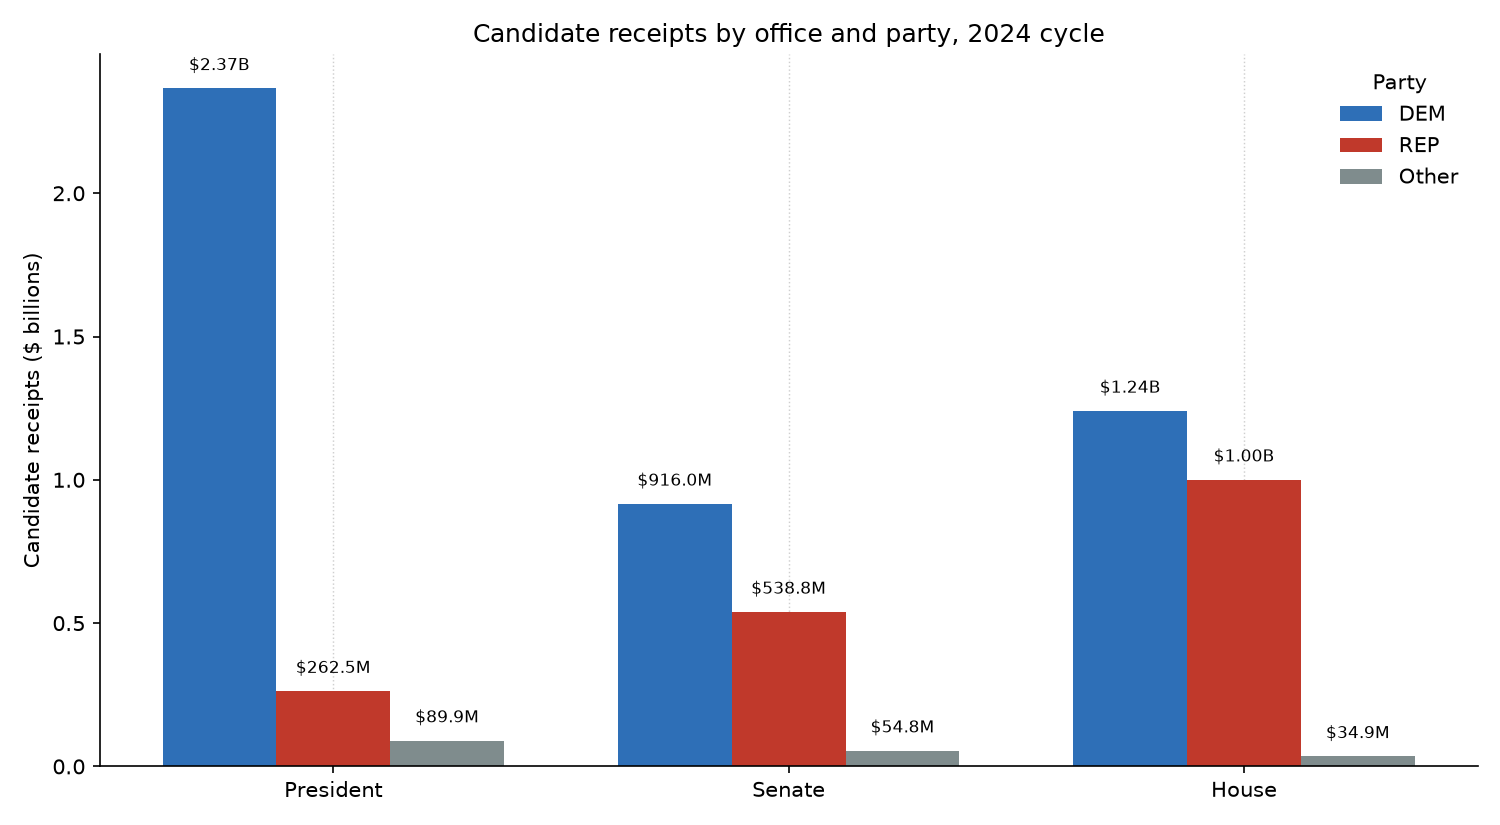

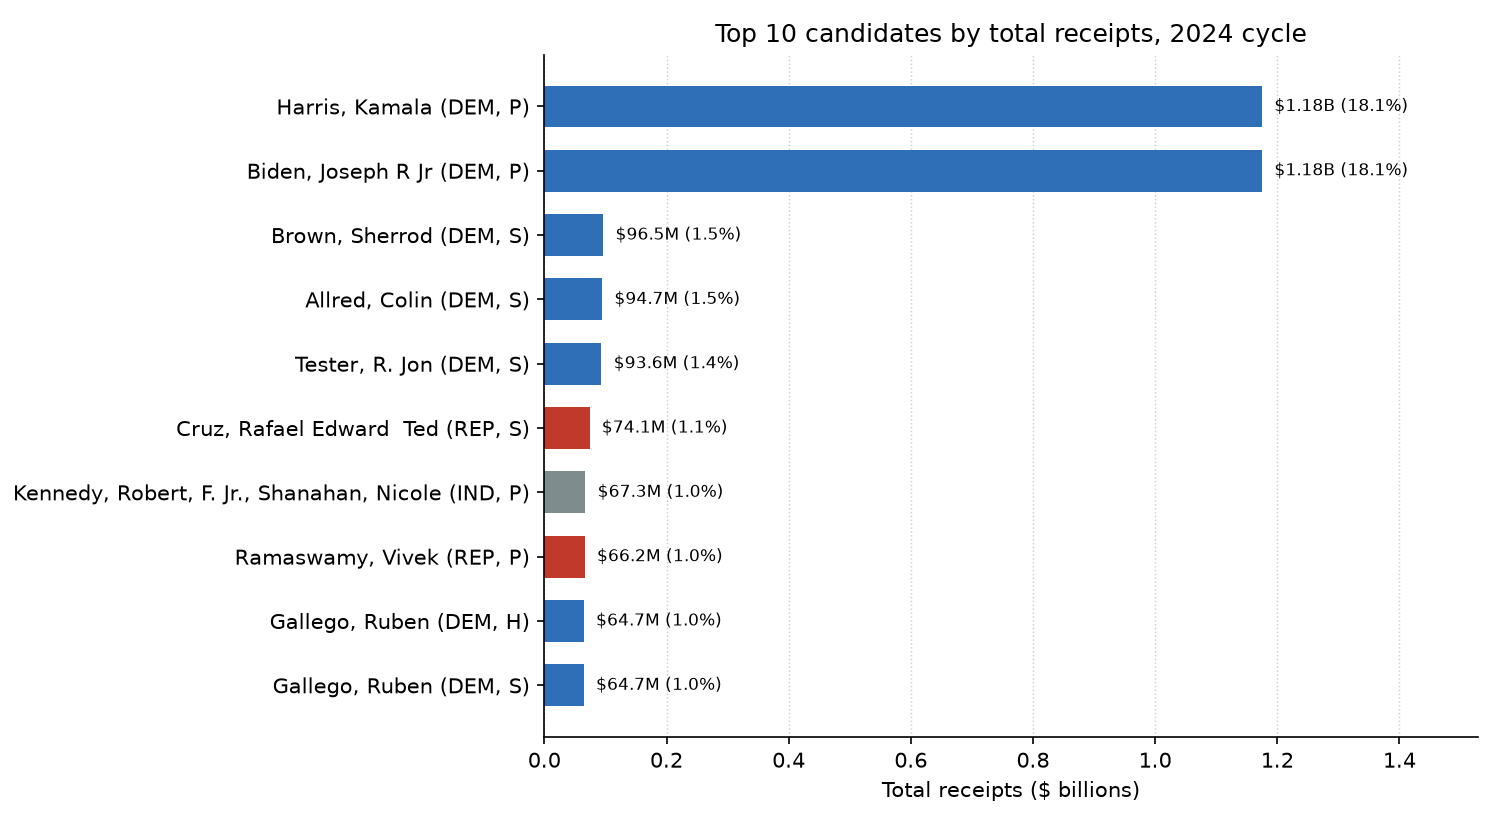

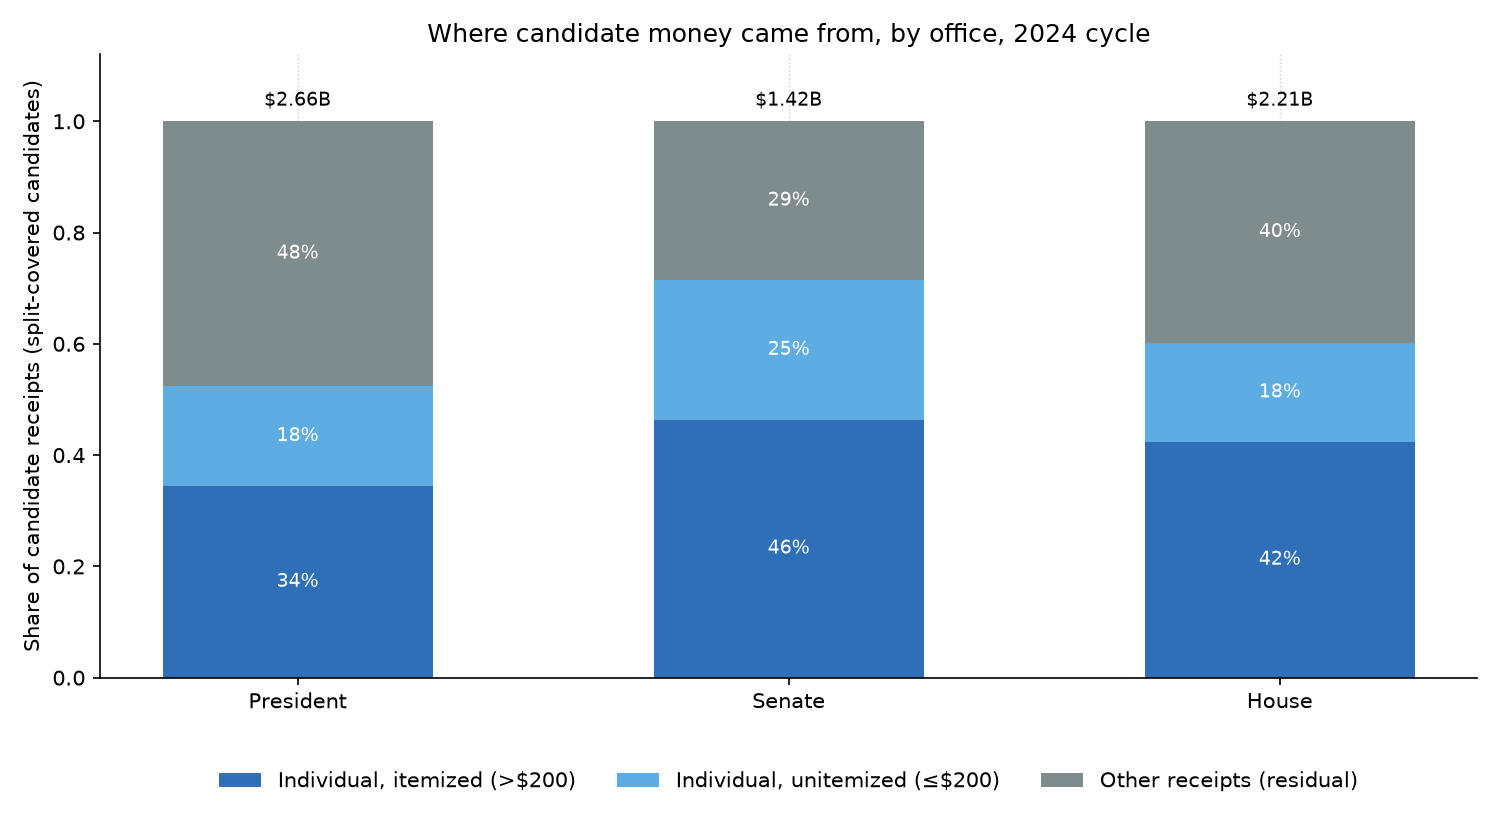

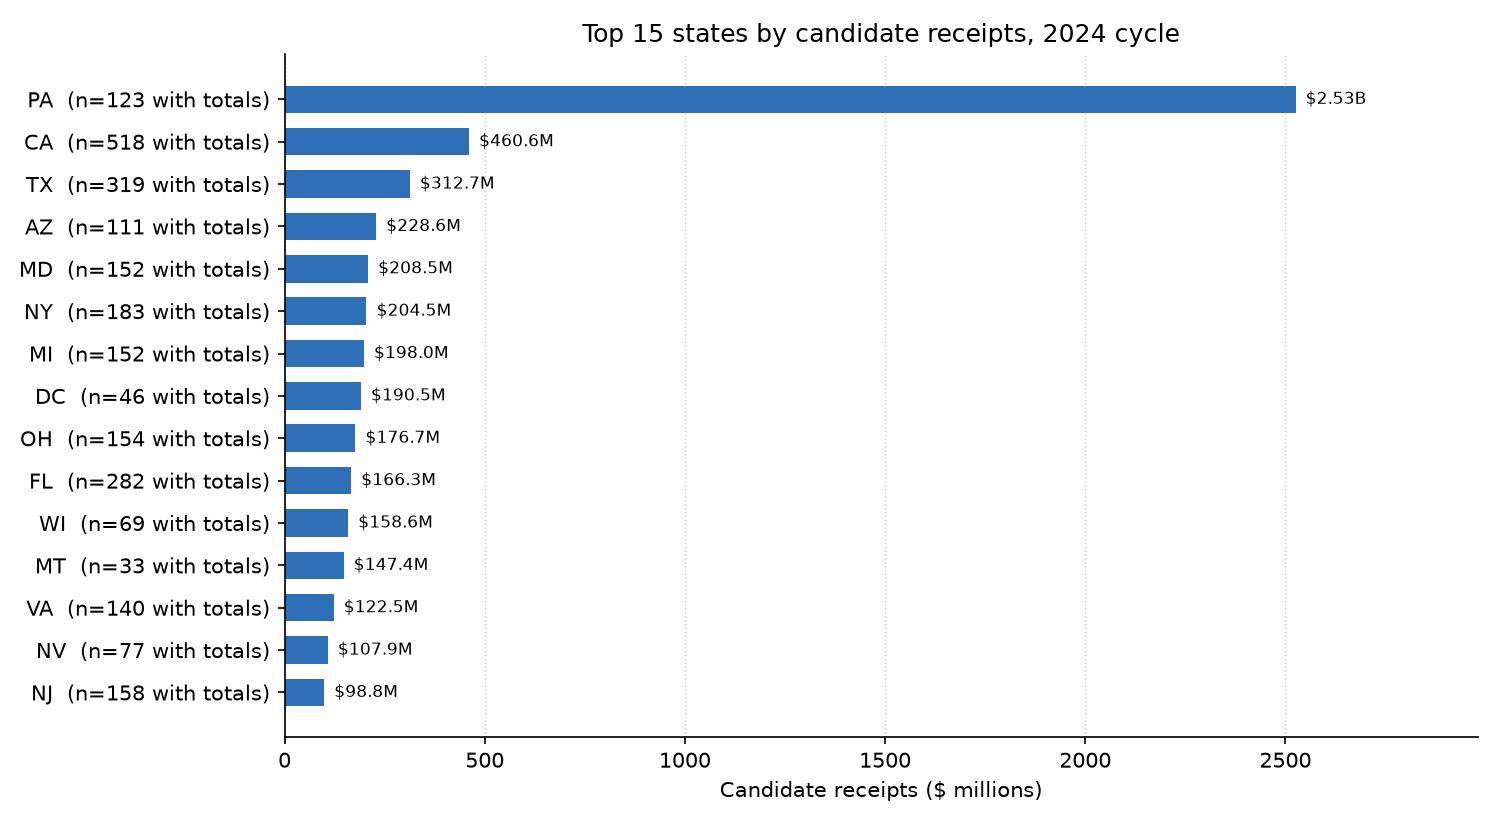

In [8]:
# 7 — Charts
from IPython.display import Image, display as _display

for name in [
    "01_receipts_by_office_party.png",
    "02_top_candidates.png",
    "03_funding_mix.png",
    "04_state_totals.png",
]:
    _display(Image(filename=str(ROOT / "outputs" / "charts" / name)))

In [9]:
# 8 — SQL check and answers to Q1-Q3
# The same question - total receipts per party, and the top party -
# answered in pandas and in SQL (in-memory SQLite, stdlib) and asserted equal.
import sqlite3

con = sqlite3.connect(":memory:")
cand.to_sql("candidates", con, index=False)
party_office.to_sql("party_office", con, index=False)
sql_top = con.execute(
    "SELECT party, SUM(receipts) AS receipts FROM candidates "
    "WHERE has_totals = 1 GROUP BY party ORDER BY receipts DESC LIMIT 1"
).fetchone()
pandas_top = (
    cand[cand["has_totals"]].groupby("party")["receipts"].sum().sort_values(ascending=False)
)
assert sql_top[0] == str(pandas_top.index[0])
assert abs(sql_top[1] - float(pandas_top.iloc[0])) < 0.01
print(f"SQL top party: {sql_top[0]} ${sql_top[1]:,.2f} — matches pandas")
sql_party = dict(con.execute(
    "SELECT party, SUM(receipts) FROM candidates WHERE has_totals = 1 GROUP BY party"
).fetchall())
for party in ["DEM", "REP"]:
    assert abs(sql_party[party] - float(pandas_top[party])) < 0.01
print("SQL == pandas for DEM and REP receipts")
print()
print("Q1 — Where did candidate money come from?")
print("  Individuals gave $3,734.5M of the $6,286.0M raised by the 2,259 split-covered")
print("  candidates (59.4%); 32.8% of individual money was small-dollar (<= $200).")
print("Q2 — How concentrated is it?")
print("  The top 10 candidates took 45.7% of candidate receipts; the top 2 (Harris/Biden,")
print("  shared committee) took 36.1%. ActBlue moved $3.82B, 16.8% of committee receipts.")
print("Q3 — How did spending compare with fundraising?")
print("  Candidates disbursed $6,728.3M against $6,503.1M raised (median burn rate 0.997);")
print("  12.2% spent more than they raised. Presidential candidates disbursed $3,038.4M,")
print("  more than House ($2,141.5M) and Senate ($1,548.4M) candidates combined.")
print()
# Guarded join re-run (plan §6): raw .txt files are git-ignored, so
# this runs only when they are present on disk; otherwise it skips
# with a note and the notebook still finishes with 0 errors.
RAW = ROOT / "data" / "raw"
if (RAW / "cn.txt").exists() and (RAW / "webk24.txt").exists() and (RAW / "ccl.txt").exists():
    import sys

    sys.path.insert(0, str(ROOT))
    from src.data_pipeline import CN_COLUMNS, WEBK_COLUMNS
    from src.finance import principal_committees

    cn_raw = pd.read_csv(RAW / "cn.txt", sep="|", header=None, names=CN_COLUMNS,
                         dtype=str, keep_default_na=False)
    principals_cn = principal_committees(cn_raw[cn_raw["election_year"] == "2024"])
    # The committed candidates.csv already carries the linkage-file fill
    # (72 rows), so the principal set is read off it directly; the raw
    # cn count is the cross-check for the pre-fill figure.
    principals = principal_committees(cand)
    assert len(principals) == record["principal_committees_distinct"]
    print(f"join re-run OK: {len(principals_cn):,} principal committees from cn; "
          f"{record['candidate_table']['principal_committee_filled_from_ccl']} rows "
          f"filled from the linkage file; {len(principals):,} distinct in total")
    wk_raw = pd.read_csv(RAW / "webk24.txt", sep="|", header=None, names=WEBK_COLUMNS,
                         dtype=str, keep_default_na=False)
    in_webk_raw = principals & set(wk_raw["committee_id"])
    print(f"{len(in_webk_raw)} in raw webk "
          f"({record['principal_committees_in_webk']} with a filed summary — the other "
          f"{len(in_webk_raw) - record['principal_committees_in_webk']} filed none)")
    assert len(principals & set(cmte["committee_id"])) == 0
    print("principal committees are absent from committees.csv, as designed")
else:
    print("raw .txt files not present — join re-run skipped; committed CSVs used")

SQL top party: DEM $4,522,002,903.20 — matches pandas
SQL == pandas for DEM and REP receipts

Q1 — Where did candidate money come from?
  Individuals gave $3,734.5M of the $6,286.0M raised by the 2,259 split-covered
  candidates (59.4%); 32.8% of individual money was small-dollar (<= $200).
Q2 — How concentrated is it?
  The top 10 candidates took 45.7% of candidate receipts; the top 2 (Harris/Biden,
  shared committee) took 36.1%. ActBlue moved $3.82B, 16.8% of committee receipts.
Q3 — How did spending compare with fundraising?
  Candidates disbursed $6,728.3M against $6,503.1M raised (median burn rate 0.997);
  12.2% spent more than they raised. Presidential candidates disbursed $3,038.4M,
  more than House ($2,141.5M) and Senate ($1,548.4M) candidates combined.

raw .txt files not present — join re-run skipped; committed CSVs used
